In [32]:
import numpy as np 
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader
import matplotlib.pyplot as plt

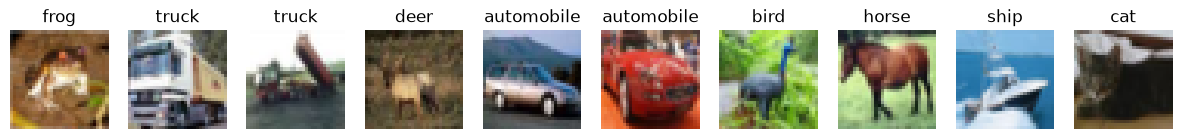

In [13]:
cifar_train = datasets.CIFAR10(root='../data', train=True, download=True) #Dataset download

fig, axes = plt.subplots(1, 10, figsize=(15,2))
for i in range(10):
    img, label = cifar_train[i]
    axes[i].imshow(img)
    axes[i].set_title(cifar_train.classes[label])
    axes[i].axis('off')

plt.show()

In [15]:
cifar_scale = cifar_train.data/255 #Scale to 0-1
print(cifar_scale.shape, cifar_scale.min(), cifar_scale.max())
mean = cifar_scale.mean(axis=(0,1,2)) #Mean per color
std = cifar_scale.std(axis=(0,1,2)) #Standard deviation per color
print(mean, std)

(50000, 32, 32, 3) 0.0 1.0
[0.49139968 0.48215841 0.44653091] [0.24703223 0.24348513 0.26158784]


In [ ]:
train_tf = transforms.Compose([transforms.RandomCrop(32, padding=4), #Padd and crop 32x32
                            transforms.RandomHorizontalFlip(), #Flip horizontally
                            transforms.ToTensor(), #Convert to Tensor from PIL
                            transforms.Normalize(mean, std)]) #Norm

test_tf = transforms.Compose([transforms.ToTensor(),
                            transforms.Normalize(mean, std)])
 

In [ ]:
train_aug = datasets.CIFAR10(root='../data', train=True, download=True, transform=train_tf) #Training set with 50,000 images and with augmentation
train_plain = datasets.CIFAR10(root='../data', train=True, download=True, transform=test_tf) #Validation set with 50,000 images but without augmentation
test_set = datasets.CIFAR10(root='../data', train=False, download=True, transform=test_tf) # 10,000 Test images with no augmentation
rng = np.random.default_rng(0) #Random number generator with seed 0
idx = rng.permutation(50000) #0-49,999 Shuffled numbers
#print(idx[:10])
train_idx = idx[:45000].tolist() #Select index for first 45000 images for training
val_idx = idx[45000:].tolist() #Select index for last 5000 images for validation
print(len(train_idx), len(val_idx))
train_set = Subset(train_aug, train_idx) #Training set is subset of Train aug with 45000 images with index from train index and same for validation
val_set = Subset(train_plain, val_idx)
print(len(train_set), len(val_set), len(test_set))

45000 5000
45000 5000 10000


torch.Size([128, 3, 32, 32]) torch.Size([128])


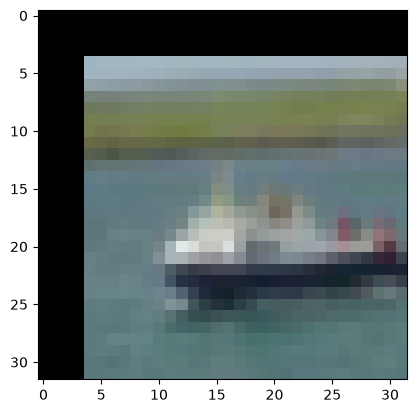

In [38]:
train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=0) #Training batch loader
val_loader = DataLoader(val_set, batch_size= 256, shuffle=False, num_workers=0) #val batch loader
test_loader = DataLoader(test_set, batch_size= 256, shuffle=False, num_workers=0) #test batch loader
images, labels = next(iter(train_loader)) #Load images and iterate
print(images.shape, labels.shape)

img = images[0] #First image of batch
img = img.permute(1, 2, 0) #Move color axis last (32, 32, 3)
img = img.numpy()
img = img * std + mean #Undo norm
img = np.clip(img, 0, 1) #Clip between 0-1
plt.imshow(img)
plt.show()
